# Demand modelling – part 2

Household-group personas from SERL data: seven features per group (electricity, gas, solar export, winter rise in each, evening-peak share, change since 2020), clustered with k-means.

**Input:** `data/Clean_Aggregated_data_2020_2023.csv` and the 2023 half-hourly file.
**Outputs:** `outputs/household_group_features.csv`, `outputs/household_group_personas.csv`.


In [ ]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

# =============================================================================
# data prep pipeline (oop version) — patched
# =============================================================================

from __future__ import annotations

# stdlib
from dataclasses import dataclass, field
from pathlib import Path
from typing import Dict, List, Optional
import io  # needed to capture df.info() text

# third-party
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------- Theme (no trailing commas!) ----------------
PRIMARY_COLOR    = "#12436D"  # Dark blue
TURQUOISE_COLOR  = "#28A197"  # Turquoise
DARK_PINK_COLOR  = "#801650"  # Dark pink
ORANGE_COLOR     = "#F46A25"  # Orange
DARK_GREY        = "#3D3D3D"  # Dark grey
LIGHT_PURPLE     = "#A285D1"  # Light purple
LIGHT_BG         = "#F5F5F5"  # Light gray background
DARK_TEXT        = "#333333"  # Dark text

PALETTE = [
    PRIMARY_COLOR, TURQUOISE_COLOR, DARK_PINK_COLOR, ORANGE_COLOR,
    DARK_GREY, LIGHT_PURPLE
]
YEAR_COLORS = {2020: PRIMARY_COLOR, 2021: TURQUOISE_COLOR, 2022: DARK_PINK_COLOR, 2023: ORANGE_COLOR}

def set_theme():
    plt.rcParams.update({
        "figure.figsize": (11, 6),
        "figure.dpi": 120,
        "figure.facecolor": "#ffffff",
        "axes.facecolor": "#ffffff",
        "axes.edgecolor": DARK_GREY,
        "axes.labelcolor": DARK_TEXT,
        "axes.titlesize": 16,
        "axes.titleweight": "bold",
        "grid.color": "#E6E6E6",
        "grid.alpha": 0.8,
        "axes.grid": True,
        "font.size": 12,
        "legend.frameon": False,
        "legend.edgecolor": "#00000000",
    })
    plt.rcParams['axes.prop_cycle'] = plt.cycler(color=PALETTE)
    # Times New Roman everywhere
    plt.rcParams.update({'font.family':'serif','font.serif':['Times New Roman','Times','serif']})

set_theme()

# =============================================================================
# configuration
# =============================================================================

@dataclass
class PrepConfig:
    """configuration for the data preparation pipeline.

    one-line summary:
        holds io paths, thresholds, and column rules for a reproducible run.

    args:
        csv_path: absolute or relative path to the input csv file.
        missing_drop_threshold: percentage (0–100) over which columns are dropped.
        rename_map: mapping from old column names to new names.
        drop_columns: explicit columns to drop after renaming (if present).
        random_seed: seed used to keep any stochastic steps reproducible.

    returns:
        none.
    """

    csv_path: Path
    missing_drop_threshold: float = 50.0
    rename_map: Dict[str, str] = field(
        default_factory=lambda: {
            # rename for clarity and consistency
            "segment_1_value": "primary_space_heating_fuel",
            "segment_2_value": "has_PV",
        }
    )
    drop_columns: List[str] = field(
        default_factory=lambda: ["segmentation_variable_1", "segmentation_variable_2", "summary_time"]
    )
    random_seed: int = 42


# =============================================================================
# pipeline
# =============================================================================

class DataPrepPipeline:
    """end-to-end data preparation and diagnostics for the energy dataset.

    one-line summary:
        loads, profiles, cleans, and returns a tidy dataframe with logs.

    args:
        config: instance of `PrepConfig` containing all run parameters.

    returns:
        none. use `.run()` to execute and retrieve the final dataframe.

    raises:
        filenotfounderror: if the csv path does not exist.
        valueerror: if input df is empty or badly formatted.
    """

    def __init__(self, config: PrepConfig):
        # keep run settings together for easy reproducibility
        self.cfg = config
        # seed numpy to keep any randomness deterministic
        np.random.seed(self.cfg.random_seed)

        # internal state holder
        self.df: Optional[pd.DataFrame] = None

    # -------------------------------------------------------------------------
    # io
    # -------------------------------------------------------------------------
    def load(self) -> pd.DataFrame:
        """load the csv with basic validation.

        returns:
            loaded dataframe.

        raises:
            filenotfounderror: if the file path is missing.
            valueerror: if the file loads but is empty.
        """
        path = Path(self.cfg.csv_path)
        if not path.exists():
            # fail early with a clear message
            raise FileNotFoundError(f"csv not found at: {path}")

        # read once; let pandas infer types reasonably
        df = pd.read_csv(path)

        if df.empty:
            # empty data is usually a bad sign worth stopping for
            raise ValueError("loaded dataframe is empty.")

        # store in state for subsequent steps
        self.df = df
        self._log(f"loaded shape: {df.shape[0]} rows × {df.shape[1]} cols")
        return df

    # -------------------------------------------------------------------------
    # quick diagnostics
    # -------------------------------------------------------------------------
    def basic_profile(self) -> dict:
        """produce a lightweight profile summary for sanity checks.

        returns:
            dictionary with head, info (as string), and describe summary.
        """
        self._ensure_loaded()

        # capture df.info() text into a string
        buf = io.StringIO()
        self.df.info(buf=buf)
        info_text = buf.getvalue()

        summary = {
            "shape": self.df.shape,
            "columns": list(self.df.columns),
            "dtypes": self.df.dtypes.astype(str).to_dict(),
            "info": info_text,
            "describe_numeric": self.df.describe().to_dict(),
            "head": self.df.head().to_dict(orient="records"),
        }

        self._log("generated basic profile.")
        return summary

    def inspect_categoricals(self) -> dict:
        """inspect object columns with counts and cardinalities.

        returns:
            mapping of column name to a small dict of stats.
        """
        self._ensure_loaded()

        cat_cols = self.df.select_dtypes(include="object").columns.tolist()
        out = {}
        for col in cat_cols:
            vc = self.df[col].value_counts(dropna=False)
            out[col] = {
                "nunique": int(self.df[col].nunique(dropna=False)),
                "top_values": vc.head(20).to_dict(),  # keep it compact
            }

        # special peek for 'quantity' if present
        if "quantity" in self.df.columns:
            out["_quantity_unique_preview"] = pd.unique(self.df["quantity"]).tolist()

        self._log(f"inspected {len(cat_cols)} categorical columns.")
        return out

    # -------------------------------------------------------------------------
    # missingness handling
    # -------------------------------------------------------------------------
    def missing_profile(self) -> pd.Series:
        """compute missing percentage per column.

        returns:
            series indexed by column with missing percentage (0–100).
        """
        self._ensure_loaded()

        missing_pct = self.df.isna().mean().mul(100).sort_values(ascending=False)
        self._log("computed missingness profile.")
        return missing_pct

    def drop_high_missing(self, missing_pct: Optional[pd.Series] = None) -> List[str]:
        """drop columns over the configured missingness threshold.

        args:
            missing_pct: optional precomputed missing series to reuse.

        returns:
            list of columns dropped.
        """
        self._ensure_loaded()

        if missing_pct is None:
            missing_pct = self.missing_profile()

        threshold = self.cfg.missing_drop_threshold
        to_drop = missing_pct[missing_pct > threshold].index.tolist()

        # drop in place if any
        if to_drop:
            self.df.drop(columns=to_drop, inplace=True, errors="ignore")
            self._log(f"dropped {len(to_drop)} high-missing columns (> {threshold}%): {to_drop}")
        else:
            self._log("no columns exceeded missingness threshold.")

        return to_drop

    # -------------------------------------------------------------------------
    # schema cleanup
    # -------------------------------------------------------------------------
    def rename_columns(self) -> Dict[str, str]:
        """rename columns using the configured mapping.

        returns:
            the mapping actually applied (only existing keys).
        """
        self._ensure_loaded()

        existing_map = {k: v for k, v in self.cfg.rename_map.items() if k in self.df.columns}
        if existing_map:
            self.df.rename(columns=existing_map, inplace=True)
            self._log(f"renamed columns: {existing_map}")
        else:
            self._log("no columns matched for renaming.")

        return existing_map

    def drop_columns(self) -> List[str]:
        """drop configured columns if they are present.

        returns:
            list of columns actually dropped.
        """
        self._ensure_loaded()

        present = [c for c in self.cfg.drop_columns if c in self.df.columns]
        if present:
            self.df.drop(columns=present, inplace=True, errors="ignore")
            self._log(f"dropped redundant columns: {present}")
        else:
            self._log("no redundant columns found to drop.")

        return present

    # -------------------------------------------------------------------------
    # orchestrator
    # -------------------------------------------------------------------------
    def run(self) -> pd.DataFrame:
        """run the full pipeline in the intended order.

        returns:
            cleaned dataframe ready for downstream work.
        """
        self.load()

        # quick, non-fatal diagnostics (kept for exploration)
        _ = self.basic_profile()
        _ = self.inspect_categoricals()

        # missingness → drop too-empty columns, then tidy names, then drop noise
        miss = self.missing_profile()
        _ = self.drop_high_missing(miss)
        _ = self.rename_columns()
        _ = self.drop_columns()

        self._log(f"final shape: {self.df.shape[0]} rows × {self.df.shape[1]} cols")
        return self.df.copy(deep=True)

    # -------------------------------------------------------------------------
    # internals
    # -------------------------------------------------------------------------
    def _ensure_loaded(self) -> None:
        """ensure dataframe is loaded before any operation.

        raises:
            runtimeerror: if `self.df` is None.
        """
        if self.df is None:
            # nudge the caller to run load()/run() first
            raise RuntimeError("dataframe is not loaded; call .load() or .run() first.")

    @staticmethod
    def _log(msg: str) -> None:
        """lightweight logger for consistent, quiet console messages.

        args:
            msg: message to print.

        returns:
            none.
        """
        print(f"[prep] {msg}")


# =============================================================================
# usage example (script entrypoint)
# =============================================================================

def main() -> None:
    """script entrypoint to run the pipeline end-to-end.

    returns:
        none.
    """
    # # todo: issue #1 add cli args via argparse if needed.

    # set up config; path can be relative to cwd
    cfg = PrepConfig(
        csv_path=Path("data/serl_daily_energy_use_in_gb_domestic_buildings_2020_to_2023_aggregated_statistics.csv"),
        missing_drop_threshold=50.0,
    )

    # run the pipeline
    pipe = DataPrepPipeline(cfg)
    cleaned = pipe.run()

    # small peek to confirm things look ok
    print("\n== preview of cleaned data ==")
    print(cleaned.head(10))


if __name__ == "__main__":
    # keep top-level side effects minimal and predictable
    main()


[prep] loaded shape: 531180 rows × 21 cols
[prep] generated basic profile.
[prep] inspected 11 categorical columns.
[prep] computed missingness profile.
[prep] no columns exceeded missingness threshold.
[prep] renamed columns: {'segment_1_value': 'primary_space_heating_fuel', 'segment_2_value': 'has_PV'}
[prep] dropped redundant columns: ['segmentation_variable_1', 'segmentation_variable_2', 'summary_time']
[prep] final shape: 531180 rows × 18 cols

== preview of cleaned data ==
              quantity            unit aggregation_period weekday_weekend  \
0                  Gas         kWh/day               2020            both   
1                  Gas         kWh/day               2020            both   
2                  Gas         kWh/day               2020            both   
3                  Gas      kWh/m2/day               2020            both   
4                  Gas      kWh/m2/day               2020            both   
5                  Gas      kWh/m2/day               2

## Household-group personas

Which kinds of households look alike once electricity, gas, solar export, seasonality, evening peak and recent change are considered together?

Each SERL household group (PV, heating fuel, region, EPC band, IMD quintile, tenure, building type and age, size, occupants, EV, …) is described by seven features. Groups with similar profiles are clustered into personas. The earlier version clustered individual entity-month *rows* (UMAP + HDBSCAN on 50,000 sampled rows, 195 clusters), so a cluster mixed months and groups, and most personas had "unknown seasonality". That analysis is replaced here.

| Feature | Definition (2023 unless stated) |
|---|---|
| electricity kWh/day | mean daily electricity imports |
| gas kWh/day | mean daily gas use |
| export kWh/day | mean daily electricity exported (solar) |
| electricity winter extra | Dec–Feb minus Jun–Aug electricity kWh/day |
| gas winter extra | Dec–Feb minus Jun–Aug gas kWh/day |
| evening share | share of daily electricity imports between 16:00 and 19:00 (half-hourly profile) |
| change since 2020 | % change in electricity imports, 2020 → 2023 |

Gas features use the available 2023 months when at least 9 of 12 are reported; groups with no gas data at all are excluded.


In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import serl_utils as su

warnings.filterwarnings("ignore", category=UserWarning)
monthly_all = su.load_monthly(su.CLEAN_CSV)
# keep only rows these analyses use (per-household kWh/day, all days) to make slicing fast
monthly = monthly_all[monthly_all["unit"].eq("kWh/day") & monthly_all["weekday_weekend"].eq("both")]

# household groups: whole sample, PV, heating fuel, and every SERL segment level except temperature band
# (temperature band describes the weather on a day, not a type of household)
SEGMENTS = [s for s in monthly["segmentation_variable_3"].dropna().unique() if s != "temperature_band"]
GROUPS = [("All households", {})]
GROUPS += [(f"PV: {v}", {"pv": v}) for v in ("Yes", "No")]
GROUPS += [(f"Heating fuel: {v}", {"fuel": v}) for v in ("Gas", "Electric")]
for seg in SEGMENTS:
    levels = sorted(monthly.loc[monthly["segmentation_variable_3"].eq(seg), "segment_3_value"].dropna().astype(str).unique())
    levels = [lv for lv in levels if lv != "All"]   # "All" repeats the whole sample
    GROUPS += [(f"{seg}: {lv}", {"segment": seg, "segment_value": lv}) for lv in levels]
print(f"{len(GROUPS)} household groups from {len(SEGMENTS)} SERL segment variables + PV + heating fuel")
hh = su.load_half_hourly([2023])
WINTER, SUMMER = [12, 1, 2], [6, 7, 8]

def winter_extra(s):
    return s[s.index.month.isin(WINTER)].mean() - s[s.index.month.isin(SUMMER)].mean()

rows, excluded = [], []
for name, f in GROUPS:
    elec = su.monthly_series(monthly, "Electricity imports", "kWh/day", **f)
    gas = su.monthly_series(monthly, "Gas", "kWh/day", **f).loc["2023"]
    export = su.monthly_series(monthly, "Electricity exports", "kWh/day", **f).loc["2023"]
    profile = su.daily_profile(hh, 2023, "Electricity imports", "Wh", **f)
    if elec.isna().any() or export.isna().any() or profile.isna().any() or gas.notna().sum() < 9:
        excluded.append(name)
        continue
    t = profile.index
    rows.append({"group": name,
                 "electricity kWh/day": elec.loc["2023"].mean(),
                 "gas kWh/day": gas.mean(),
                 "export kWh/day": export.mean(),
                 "electricity winter extra": winter_extra(elec.loc["2023"]),
                 "gas winter extra": winter_extra(gas.dropna()),
                 "evening share %": 100 * profile[(t >= "16:00") & (t < "19:00")].sum() / profile.sum(),
                 "change since 2020 %": 100 * (elec.loc["2023"].mean() / elec.loc["2020"].mean() - 1)})
features = pd.DataFrame(rows).set_index("group")
print(f"{len(features)} groups described; excluded (no gas or incomplete data): {excluded}")
print(features.describe().loc[["mean", "std", "min", "max"]].round(2).to_string())
features.to_csv("outputs/household_group_features.csv")

75 household groups from 11 SERL segment variables + PV + heating fuel


72 groups described; excluded (no gas or incomplete data): ['central_heating_type: District or community', 'central_heating_type: Oil, solid fuel or biomass', 'central_heating_type: Other electric']
      electricity kWh/day  gas kWh/day  export kWh/day  electricity winter extra  gas winter extra  evening share %  change since 2020 %
mean                 9.08        29.07            0.34                      4.09             46.12            16.05               -18.36
std                  2.38         7.45            0.53                      2.35             12.10             1.19                 3.87
min                  5.24        13.92            0.00                      1.96             21.56             8.90               -33.05
max                 17.06        57.47            4.54                     14.59             90.99            17.34                -4.02


### Personas

Features are standardised (mean 0, sd 1) and clustered with k-means for k = 2–7; k is the largest value within 0.01 of the best silhouette score. Each persona is named after the two features that differ most from the average group (in standard deviations).


silhouette by k: {2: 0.556, 3: 0.56, 4: 0.55, 5: 0.363, 6: 0.287, 7: 0.266} -> k = 3

Persona averages (original units)
                                                              groups  electricity kWh/day  gas kWh/day  export kWh/day  electricity winter extra  gas winter extra  evening share %  change since 2020 %
persona                                                                                                                                                                                                 
P1: Higher electricity use, higher gas use                         7                13.98        42.86            1.04                      6.53             67.30            14.90               -14.70
P2: Higher electricity winter rise, lower evening-peak share       4                12.84        20.96            0.22                     12.17             31.84            13.19               -19.66
P3: Lower electricity winter rise, lower electricity use          61        

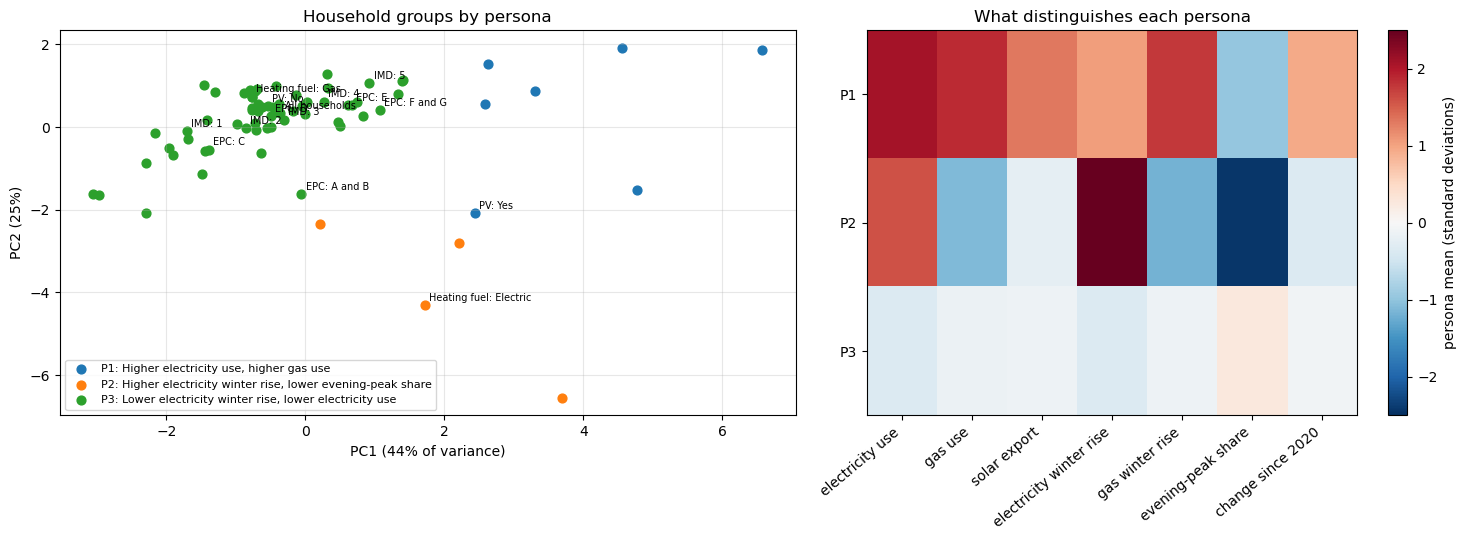

In [2]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

Z = pd.DataFrame(StandardScaler().fit_transform(features), index=features.index, columns=features.columns)
scores = {k: silhouette_score(Z, KMeans(k, n_init=20, random_state=42).fit_predict(Z)) for k in range(2, 8)}
k = max(kk for kk, s in scores.items() if s >= max(scores.values()) - 0.01)
labels = KMeans(k, n_init=20, random_state=42).fit_predict(Z)
print("silhouette by k:", {kk: round(v, 3) for kk, v in scores.items()}, "-> k =", k)

SHORT = {"electricity kWh/day": "electricity use", "gas kWh/day": "gas use", "export kWh/day": "solar export",
         "electricity winter extra": "electricity winter rise", "gas winter extra": "gas winter rise",
         "evening share %": "evening-peak share", "change since 2020 %": "change since 2020"}
centre_z = Z.groupby(labels).mean()
def persona_name(z):
    top = z.abs().sort_values(ascending=False).index[:2]
    return ", ".join(f"{'higher' if z[f] > 0 else 'lower'} {SHORT[f]}" for f in top).capitalize()
names = {c: f"P{i + 1}: {persona_name(centre_z.loc[c])}" for i, c in enumerate(centre_z.index)}

personas = features.assign(persona=[names[c] for c in labels])
summary = personas.groupby("persona").mean().round(2)
summary.insert(0, "groups", personas["persona"].value_counts())
print("\nPersona averages (original units)")
print(summary.to_string())
for p, members in personas.groupby("persona").groups.items():
    print(f"\n{p} — {len(members)} groups:\n  " + "; ".join(members))
personas.to_csv("outputs/household_group_personas.csv")
print("\nSaved outputs/household_group_features.csv and outputs/household_group_personas.csv")

pcs = PCA(2, random_state=42).fit(Z)
xy = pcs.transform(Z)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.2, 1]})
for c in sorted(set(labels)):
    sel = labels == c
    axes[0].scatter(xy[sel, 0], xy[sel, 1], s=40, label=names[c])
for i, g in enumerate(Z.index):
    if g.startswith(("All households", "PV:", "Heating fuel", "IMD_quintile", "currentEnergyRating")):
        axes[0].annotate(g.replace("currentEnergyRating", "EPC").replace("IMD_quintile", "IMD"), xy[i], fontsize=7,
                         xytext=(3, 3), textcoords="offset points")
axes[0].set_xlabel(f"PC1 ({100 * pcs.explained_variance_ratio_[0]:.0f}% of variance)")
axes[0].set_ylabel(f"PC2 ({100 * pcs.explained_variance_ratio_[1]:.0f}%)")
axes[0].set_title("Household groups by persona"); axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
im = axes[1].imshow(centre_z.rename(index=names).to_numpy(), cmap="RdBu_r", vmin=-2.5, vmax=2.5, aspect="auto")
axes[1].set_xticks(range(Z.shape[1]), [SHORT[c] for c in Z.columns], rotation=40, ha="right")
axes[1].set_yticks(range(len(names)), [names[c].split(":")[0] for c in centre_z.index])
fig.colorbar(im, ax=axes[1], label="persona mean (standard deviations)")
axes[1].set_title("What distinguishes each persona")
plt.tight_layout(); plt.show()

**Reading the results** (persona numbers refer to this run)
- **Larger households** (5+ bedrooms or occupants, over 150 m², EV owners, PV homes) form the high-use persona: more electricity and gas, and a smaller fall since 2020.
- **Electric heating** forms its own persona: a steep winter rise in electricity and a smaller share of use at 16:00–19:00, consistent with heating spread across the day and night (e.g. storage heaters).
- **Everyone else** (61 groups, including every region, tenure, EPC band and IMD quintile) shares a typical profile. Differences between deprivation quintiles are mainly in *how much* electricity is used (see the features table), not in the pattern. Heating fuel and dwelling size, rather than region or deprivation, define the distinct demand personas.
